# ATML PA3 — Task 3: Test-Time Compute (sampling, selection, refinement, adaptive inference)

**Before running:** put the supplied `ATML-PA3-Data` folder in your Drive (default path below) and read its
`README.MD`. Cell 3 prints the column names it finds; if any automatic column match is wrong, fix it in `COL_OVERRIDES`.

Steps 1–3 and 5–6 are offline (CPU is enough). Step 4 (live generation, 50 MATH questions) needs a GPU.
**Resume:** answer groups/correctness, per-question offline results and every live-generation call are saved to
Drive as they are produced; after a disconnect simply "Run all" again.

Outputs: `MyDrive/ATML_PA3/task3/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install "math-verify[antlr4_13_2]" levenshtein pyarrow pandas scipy matplotlib "transformers>=4.45,<5" accelerate datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
# Configuration
import os, json, math, time, re, gc, glob, random
from pathlib import Path
from collections import Counter, defaultdict
from importlib.metadata import version
import numpy as np, pandas as pd
from scipy.stats import rankdata, spearmanr, pearsonr

DATA_DIR = Path("/content/drive/MyDrive/ATML-PA3-Data")      # <-- supplied rollouts
ROOT = Path("/content/drive/MyDrive/ATML_PA3/task3"); ROOT.mkdir(parents=True, exist_ok=True)
for d in ["cache", "offline", "live", "adaptive", "figures"]: (ROOT / d).mkdir(exist_ok=True)

SEED = 6304
NS = [1, 2, 4, 8, 16, 32]
N_ORDERS = 10
N_DEV = 200
N_BOOT = 1000
NO_ANSWER = "NO_ANSWER"
TAUS = [0.5, 0.625, 0.75, 0.875, 1.0]
GAMMAS = [0.0, 0.1, 0.25, 0.5]
CHECKS = [4, 8, 16]

# Live generation (Step 4)
LIVE_MODEL = "Qwen/Qwen2.5-3B-Instruct"
LIVE_REVISION = "aa8e72537993ba99e69dfaafa59ed015b17504d1"   # pinned in the supplied README.MD
LIVE_SYSTEM = "You are a helpful assistant."
LIVE_INSTR = "Think step by step inside <think> </think> tags, then give your final answer inside \\boxed{}."
LIVE_SEP = "\n\n"             # README.MD: problem, two newlines, instruction
REVIEW_INSTR = ("Review the solution above. Identify and correct any errors; if it is correct, retain its answer. "
                "Give your final answer inside \\boxed{}.")
LIVE_N = 50
GEN_KW = dict(do_sample=True, temperature=0.7, top_p=0.8, top_k=20, repetition_penalty=1.0)

COL_OVERRIDES = {}            # e.g. {"pred": "extracted_answer", "att_img": "image_attn"} if auto-detection is wrong
print("math-verify", version("math-verify"))

math-verify 0.9.0


In [4]:
# Step 1a — load and join the supplied tables, verify token-list alignment
gen_files = sorted(DATA_DIR.rglob("generations.parquet"))
if not gen_files:   # not at DATA_DIR: look for the folder (or a zip of it) anywhere in My Drive
    print(f"{DATA_DIR} has no generations.parquet — searching My Drive (can take a minute) ...")
    hits = sorted(glob.glob("/content/drive/MyDrive/**/generations.parquet", recursive=True))
    zips = sorted(glob.glob("/content/drive/MyDrive/**/*PA3*Data*.zip", recursive=True))
    print("found parquet:", hits[:6], "| found zips:", zips[:4])
    if hits:
        DATA_DIR = Path(os.path.commonpath([str(Path(h).parent.parent) for h in hits]))
    elif zips:
        import zipfile
        out = Path("/content/ATML-PA3-Data")
        with zipfile.ZipFile(zips[0]) as z: z.extractall(out)
        DATA_DIR = out
    gen_files = sorted(DATA_DIR.rglob("generations.parquet"))
assert gen_files, ("Could not find the supplied rollouts. Put the ATML-PA3-Data folder in My Drive (if it was shared "
                   "with you, right-click it in 'Shared with me' -> Organize -> Add shortcut -> My Drive) and set DATA_DIR.")
print("using DATA_DIR =", DATA_DIR)
FOLDERS = {}
for f in gen_files:
    kind = "vlm" if (f.parent / "attention_metrics.parquet").exists() else "llm"
    FOLDERS["mathvista" if kind == "vlm" else "math"] = f.parent
print(FOLDERS)
for p in DATA_DIR.rglob("README*"): print("README:", p)
for nm, d in FOLDERS.items():
    for fn in ["generations", "probability_metrics", "attention_metrics"]:
        if (d / f"{fn}.parquet").exists():
            import pyarrow.parquet as pq
            print(f"{nm}/{fn}: {pq.read_schema(d / f'{fn}.parquet').names}")

CAND = {   # first entries = the column names of the supplied ATML-PA3-Data export
    "dataset": ["dataset"], "sample_id": ["sample_id"], "rollout_id": ["rollout_id"],
    "text": ["generated_text", "text", "response", "generation", "completion", "output_text", "output"],
    "token_ids": ["generated_token_ids", "token_ids", "output_token_ids", "tokens"],
    "n_tokens": ["n_generated_text_tokens", "num_tokens", "n_tokens", "num_generated_tokens", "generated_length", "output_length", "token_count"],
    "hit_max": ["hit_max_new_tokens"],
    "pred": ["extracted_answer", "pred_answer", "predicted_answer", "extracted", "prediction", "pred"],
    "gold": ["gold_answer", "gold", "answer_gold", "ground_truth", "reference_answer", "answer"],
    "problem": ["question_text", "problem", "question", "query"],
    "logp": ["logp", "token_logp", "logprobs"], "kl": ["kl_u_p"],
}
def pick(df, key):
    if key in COL_OVERRIDES: return COL_OVERRIDES[key]
    for c in CAND.get(key, []):
        if c in df.columns: return c
    return None

KEYS = ["dataset", "sample_id", "rollout_id"]
def load_model_data(nm):
    d = FOLDERS[nm]
    g = pd.read_parquet(d / "generations.parquet"); p = pd.read_parquet(d / "probability_metrics.parquet")
    df = g.merge(p, on=KEYS, how="inner", suffixes=("", "_prob"))
    assert len(df) == len(g) == len(p), f"{nm}: join lost rows ({len(g)}, {len(p)}, {len(df)})"
    cols = {k: pick(df, k) for k in CAND}
    if nm == "mathvista":
        a = pd.read_parquet(d / "attention_metrics.parquet")
        df = df.merge(a, on=KEYS, how="inner", suffixes=("", "_att")); assert len(df) == len(g)
        is_seq = lambda c: hasattr(df[c].iloc[0], "__len__") and not isinstance(df[c].iloc[0], str)
        exact = {"att_img": "img_attn_total", "att_prompt": "prompt_text_attn_total", "att_gen": "generated_text_attn_total"}
        def find(sub):
            if sub in COL_OVERRIDES: return COL_OVERRIDES[sub]
            if exact[sub] in df.columns: return exact[sub]
            pat = {"att_img": r"image|img|vis", "att_prompt": r"prompt", "att_gen": r"generat|gen_|output|response"}[sub]
            m = [c for c in a.columns if c not in KEYS and "attn" in c.lower() and re.search(pat, c, re.I) and is_seq(c)]
            return m[0] if m else None
        for sub in ["att_img", "att_prompt", "att_gen"]: cols[sub] = find(sub)
    print(nm, "column map:", cols)
    for k in ["sample_id", "rollout_id", "pred", "gold", "logp", "kl"]:
        assert cols[k], f"{nm}: could not find column for '{k}' — set COL_OVERRIDES"
    if nm == "mathvista":
        assert all(cols[k] for k in ["att_img", "att_prompt", "att_gen"]), "set attention columns in COL_OVERRIDES"
        for k in ["att_img", "att_prompt", "att_gen"]:
            v = df[cols[k]].iloc[0]
            assert hasattr(v, "__len__") and not isinstance(v, str), (
                f"{cols[k]} holds one number per rollout, but visual engagement needs one value per generated token "
                f"— check README.MD and set COL_OVERRIDES['{k}'] to the per-token column")
    return df, cols

DATA = {nm: load_model_data(nm) for nm in FOLDERS}
README_TOTALS = {"math": {"retained_tokens": 20_742_094, "capped": 523, "null_extracted": 521},
                 "mathvista": {"retained_tokens": 8_961_703, "capped": 487, "null_extracted": 3_032}}
for nm, (df, cols) in DATA.items():
    T = df[cols["logp"]].map(len)
    checks = {"rows": len(df), "questions": df[cols["sample_id"]].nunique(),
              "rollouts_per_question": df.groupby(cols["sample_id"]).size().unique().tolist(),
              "len(logp)!=len(kl)": int((T != df[cols["kl"]].map(len)).sum())}
    if cols["token_ids"]: checks["len(token_ids)-len(logp) counts"] = {str(k): v for k, v in Counter((df[cols["token_ids"]].map(len) - T).tolist()).most_common(5)}
    if cols["n_tokens"]: checks["n_tokens-len(logp) counts"] = {str(k): v for k, v in Counter((df[cols["n_tokens"]] - T).tolist()).most_common(5)}
    if cols["hit_max"]: checks["hit_max_new_tokens_rate"] = float(df[cols["hit_max"]].mean())
    got = {"retained_tokens": int(T.sum()), "capped": int(df[cols["hit_max"]].sum()) if cols["hit_max"] else None,
           "null_extracted": int(df[cols["pred"]].isna().sum())}
    checks["matches_README_totals"] = {k: (got[k], README_TOTALS[nm][k], got[k] == README_TOTALS[nm][k]) for k in got}
    if nm == "mathvista":
        for k in ["att_img", "att_prompt", "att_gen"]: checks[f"len({k})!=len(logp)"] = int((df[cols[k]].map(len) != T).sum())
    print(nm, json.dumps(checks, default=str))
    json.dump(checks, open(ROOT / "cache" / f"{nm}_alignment_checks.json", "w"), default=str, indent=1)

using DATA_DIR = /content/drive/MyDrive/ATML-PA3-Data
{'math': PosixPath('/content/drive/MyDrive/ATML-PA3-Data/qwen25-math'), 'mathvista': PosixPath('/content/drive/MyDrive/ATML-PA3-Data/qwen25vl-mathvista')}
README: /content/drive/MyDrive/ATML-PA3-Data/README.MD
math/generations: ['dataset', 'model', 'sample_id', 'rollout_id', 'question_text', 'generated_token_ids', 'n_generated_text_tokens', 'hit_max_new_tokens', 'generated_text', 'gold_answer', 'extracted_answer']
math/probability_metrics: ['dataset', 'sample_id', 'rollout_id', 'logp', 'kl_u_p']
mathvista/generations: ['dataset', 'model', 'sample_id', 'rollout_id', 'question_text', 'generated_token_ids', 'n_generated_text_tokens', 'hit_max_new_tokens', 'generated_text', 'gold_answer', 'extracted_answer']
mathvista/probability_metrics: ['dataset', 'sample_id', 'rollout_id', 'logp', 'kl_u_p']
mathvista/attention_metrics: ['dataset', 'sample_id', 'rollout_id', 'n_image_tokens', 'n_prompt_text_tokens', 'n_generated_text_tokens', 'img_at

In [5]:
# Step 1b — answer normalisation, answer groups (formed WITHOUT gold) and correctness labels (cached)
from math_verify import parse as mv_parse, verify as mv_verify
import Levenshtein

def is_missing(a):
    return a is None or (isinstance(a, float) and np.isnan(a)) or str(a).strip() in ("", "None", "nan")

def _parse_math(s):
    for cand in (f"\\boxed{{{s}}}", f"${s}$", s):
        try:
            p = mv_parse(cand, parsing_timeout=5)
            if p: return p
        except Exception: pass
    return None

def _eq_math(pa, pb):
    try: return bool(mv_verify(pa, pb, timeout_seconds=5)) or bool(mv_verify(pb, pa, timeout_seconds=5))
    except Exception: return False

def _sq(s): return re.sub(r"\s+", "", str(s)).rstrip(".")

def group_math(answers, gold):
    """Representative-based clustering by math-verify equivalence (in rollout order), then grading vs gold."""
    reps, gid = [], []                     # reps: (squeezed string, parsed)
    for a in answers:
        if is_missing(a): gid.append(-1); continue
        sq, pa = _sq(a), None
        hit = next((j for j, (rs, _) in enumerate(reps) if rs == sq), None)
        if hit is None:
            pa = _parse_math(a)
            if pa is not None:
                hit = next((j for j, (_, rp) in enumerate(reps) if rp is not None and _eq_math(rp, pa)), None)
        if hit is None: reps.append((sq, pa)); hit = len(reps) - 1
        gid.append(hit)
    pg = _parse_math(gold)
    gcorrect = [(rs == _sq(gold)) or (pg is not None and rp is not None and _eq_math(pg, rp)) for rs, rp in reps]
    return gid, gcorrect, [rs for rs, _ in reps]

# ---- MathVista (answer type, choice and precision rules) ----
def _clean(s):
    s = str(s).strip()
    s = re.sub(r"\\text\{([^}]*)\}|\\mathrm\{([^}]*)\}", lambda m: m.group(1) or m.group(2), s)
    s = s.replace("$", "").replace("\\%", "").replace("%", "").replace("^\\circ", "").replace("°", "").replace("\\,", "")
    s = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)
    return s.strip().rstrip(".").strip()

def _to_float(s):
    try: return float(s)
    except Exception: pass
    m = re.fullmatch(r"\\d?frac\{(-?[\d.]+)\}\{(-?[\d.]+)\}", s) or re.fullmatch(r"(-?[\d.]+)\s*/\s*(-?[\d.]+)", s)
    if m:
        try: return float(m.group(1)) / float(m.group(2))
        except Exception: return None
    p = _parse_math(s)
    if p:
        try: return float(p[0].evalf())
        except Exception: return None
    return None

def mathvista_norm(ans, meta):
    if is_missing(ans): return NO_ANSWER
    s = _clean(ans)
    if meta["question_type"] == "multi_choice":
        ch = [str(c).strip() for c in meta["choices"]]; letters = [chr(65 + i) for i in range(len(ch))]
        m = re.fullmatch(r"\(?([A-Za-z])\)?[.):]?", s)
        if m and m.group(1).upper() in letters: return m.group(1).upper()
        m = re.match(r"^\(?([A-Z])\)[\s.:]|^([A-Z])[.:]\s", s)
        if m and (m.group(1) or m.group(2)) in letters: return m.group(1) or m.group(2)
        if s in ch: return letters[ch.index(s)]
        low = [c.lower() for c in ch]
        if s.lower() in low: return letters[low.index(s.lower())]
        return letters[int(np.argmin([Levenshtein.distance(s, c) for c in ch]))]   # MathVista: most similar choice
    at = meta["answer_type"]
    if at == "integer":
        f = _to_float(s); return str(int(f)) if f is not None and np.isfinite(f) else "RAW:" + s
    if at == "float":
        f = _to_float(s); prec = int(meta["precision"]) if meta.get("precision") not in (None, "") and not pd.isna(meta.get("precision")) else 1
        return str(round(f, prec)) if f is not None and np.isfinite(f) else "RAW:" + s
    if at == "list": return re.sub(r"\s+", "", s)
    return s.lower()

def mathvista_gold(meta):
    if meta["question_type"] == "multi_choice":
        ch = [str(c).strip() for c in meta["choices"]]
        g = str(meta["answer"]).strip()
        return chr(65 + ch.index(g)) if g in ch else mathvista_norm(g, meta)
    return mathvista_norm(meta["answer"], meta)

def mathvista_meta(sample_ids, df, cols):
    need = ["question_type", "answer_type", "choices", "precision"]
    if all(c in df.columns for c in need):
        first = df.drop_duplicates(cols["sample_id"]).set_index(cols["sample_id"])
        return {sid: {**{c: first.loc[sid, c] for c in need}, "answer": first.loc[sid, cols["gold"]]} for sid in sample_ids}
    meta_path = ROOT / "cache" / "mathvista_testmini.json"      # released metadata linked in the assignment
    if not meta_path.exists():
        import urllib.request
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/lupantech/MathVista/main/data/testmini.json", meta_path)
        except Exception as e:
            print("GitHub download failed, using the Hugging Face copy:", e)
            from datasets import load_dataset
            mv = load_dataset("AI4Math/MathVista", split="testmini")
            mv = mv.remove_columns([c for c in mv.column_names if c in ("image", "decoded_image")])
            json.dump({str(r["pid"]): {k: r[k] for k in ["pid", "question_type", "answer_type", "choices", "precision", "answer"]}
                       for r in mv}, open(meta_path, "w"))
    by_pid = {str(k): v for k, v in json.load(open(meta_path)).items()}
    out = {}
    for sid in sample_ids:
        k = str(sid) if str(sid) in by_pid else re.sub(r"\D", "", str(sid)).lstrip("0")
        if k not in by_pid:
            raise KeyError(f"MathVista sample_id {sid!r} does not match a testmini pid (e.g. {list(by_pid)[:3]}); "
                           "check README.MD for how sample_id maps to pid")
        r = by_pid[k]
        out[sid] = {"question_type": r["question_type"], "answer_type": r["answer_type"], "choices": r["choices"] or [],
                    "precision": r["precision"], "answer": r["answer"]}
    return out

def prepare(nm):
    """Per-question arrays in rollout_id order: group ids, group correctness, cost tokens, scores, token arrays."""
    path = ROOT / "cache" / f"{nm}_prepared.pkl"; part = ROOT / "cache" / f"{nm}_prepared.partial.pkl"
    if path.exists(): return pd.read_pickle(path)
    df, cols = DATA[nm]
    df = df.sort_values([cols["sample_id"], cols["rollout_id"]])
    sids = sorted(df[cols["sample_id"]].unique(), key=str)
    meta = mathvista_meta(sids, df, cols) if nm == "mathvista" else None
    Q = pd.read_pickle(part) if part.exists() else {}      # resume a half-finished grouping pass
    t0 = time.time()
    for qi, (sid, g) in enumerate(df.groupby(cols["sample_id"], sort=False)):
        if sid in Q: continue
        answers = g[cols["pred"]].tolist(); gold = g[cols["gold"]].iloc[0]
        if nm == "math":
            gid, gcorr, reps = group_math(answers, str(gold))
        else:
            normed = [mathvista_norm(a, meta[sid]) for a in answers]
            gold_n = mathvista_gold(meta[sid])
            reps = sorted({x for x in normed if x != NO_ANSWER}, key=normed.index)
            gid = [-1 if x == NO_ANSWER else reps.index(x) for x in normed]
            gcorr = [r == gold_n for r in reps]
        lp = [np.asarray(x, dtype=np.float64) for x in g[cols["logp"]]]
        kl = [np.asarray(x, dtype=np.float64) for x in g[cols["kl"]]]
        T = np.array([len(x) for x in lp])
        cost = (g[cols["n_tokens"]].to_numpy() if cols["n_tokens"] else
                (g[cols["token_ids"]].map(len).to_numpy() if cols["token_ids"] else T)).astype(np.int64)
        rec = {"sample_id": sid, "rollout_ids": g[cols["rollout_id"]].tolist(), "gid": np.array(gid),
               "hit_max": (g[cols["hit_max"]].to_numpy().astype(bool) if cols["hit_max"] else np.zeros(len(g), bool)),
               "group_correct": np.array(gcorr + [False], dtype=bool),    # index -1 -> NO_ANSWER (always wrong)
               "reps": reps, "gold": gold, "answers": answers, "cost": cost, "T": T,
               "L": np.array([x.mean() if len(x) else -np.inf for x in lp]),
               "K": np.array([x.mean() if len(x) else -np.inf for x in kl])}
        rec["correct"] = rec["group_correct"][rec["gid"]]
        if nm == "mathvista":
            ai, ap, ag = ([np.asarray(x, dtype=np.float64) for x in g[cols[c]]] for c in ["att_img", "att_prompt", "att_gen"])
            v = [im / np.maximum(im + pr + ge, 1e-12) for im, pr, ge in zip(ai, ap, ag)]
            rec["k_tok"], rec["v_tok"] = [x.astype(np.float32) for x in kl], [x.astype(np.float32) for x in v]
            rec["V"] = np.array([x.mean() if len(x) else -np.inf for x in v])
            rec["meta"] = meta[sid]
        Q[sid] = rec
        if qi % 100 == 0: print(f"{nm}: {qi} questions prepared ({time.time() - t0:.0f}s)")
        if qi % 200 == 199: pd.to_pickle(Q, part)
    Q = {sid: Q[sid] for sid in sorted(Q, key=str)}
    pd.to_pickle(Q, path); part.unlink(missing_ok=True); return Q

PREP = {nm: prepare(nm) for nm in FOLDERS}
for nm, Q in PREP.items():
    acc = np.mean([q["correct"].mean() for q in Q.values()])
    na = np.mean([(q["gid"] == -1).mean() for q in Q.values()])
    print(f"{nm}: {len(Q)} questions | mean rollout accuracy {100 * acc:.1f}% | NO_ANSWER rate {100 * na:.2f}%")
json.dump({"math-verify": version("math-verify"), "Levenshtein": version("levenshtein")}, open(ROOT / "cache" / "scorer_versions.json", "w"))

# development / held-out split and the fixed rollout orders
SPLITS, ORDERS = {}, {}
for nm, Q in PREP.items():
    ids = sorted(Q, key=str)
    perm = np.random.default_rng(SEED).permutation(len(ids))
    order = [ids[i] for i in perm]
    SPLITS[nm] = {"dev": order[:N_DEV], "eval": order[N_DEV:]}
    rng = np.random.default_rng(SEED)
    ORDERS[nm] = {sid: np.stack([rng.permutation(len(Q[sid]["gid"])) for _ in range(N_ORDERS)]) for sid in ids}
    json.dump({k: [str(x) for x in v] for k, v in SPLITS[nm].items()}, open(ROOT / "cache" / f"{nm}_splits.json", "w"))
    json.dump({str(s): o.tolist() for s, o in ORDERS[nm].items()}, open(ROOT / "cache" / f"{nm}_orders.json", "w"))

math: 1000 questions | mean rollout accuracy 66.3% | NO_ANSWER rate 1.63%
mathvista: 1000 questions | mean rollout accuracy 54.4% | NO_ANSWER rate 9.47%


In [6]:
# Step 2 — selection rules (FirstAns, self-consistency, highest score, RWC; VisConf with per-prefix calibration)
def vote(gids, weights=None):
    """Answer group with the largest (weighted) vote; ties -> earliest supporting rollout in the current order."""
    tot, first = defaultdict(float), {}
    for pos, g in enumerate(gids):
        tot[g] += 1.0 if weights is None else weights[pos]
        first.setdefault(g, pos)
    best = max(tot, key=lambda g: (tot[g], -first[g]))
    return best, tot

def highest(scores):
    s = np.where(np.isfinite(scores), scores, -np.inf)
    return int(np.argmax(s))                      # first maximum = earliest in the current order

def rwc_weights(scores):
    N = len(scores)
    if N == 1: return np.ones(1)
    s = np.where(np.isfinite(scores), scores, -1e300)
    r = rankdata(-s, method="average")            # rank 1 = best, average ranks for ties
    return (N - r) / (N - 1)

def visconf_scores(q, idx):
    """VisConf on the CURRENT candidate set only: pooled token KL -> 5th/95th percentile calibration."""
    ks = [q["k_tok"][i] for i in idx]
    pool = np.concatenate([k for k in ks if len(k)]) if any(len(k) for k in ks) else np.zeros(1)
    lo, hi = np.percentile(pool, [5, 95])          # linear interpolation (numpy default)
    den = max(hi - lo, 1e-8)
    C, Zt = np.full(len(idx), -np.inf), np.full(len(idx), -np.inf)
    for j, i in enumerate(idx):
        k, v = q["k_tok"][i], q["v_tok"][i]
        if len(k):
            c = np.clip((k - lo) / den, 0, 1); C[j] = c.mean(); Zt[j] = (c * v).mean()
    V = q["V"][idx]
    return C, V * C, Zt

def methods_for(nm):
    m = ["first", "sc", "best_logp", "best_selfcert", "rwc_selfcert", "rwc_logp", "shortest"]
    if nm == "mathvista": m += ["best_vision", "rwc_vision", "best_visconf", "rwc_visconf", "best_visconf_tok", "rwc_visconf_tok"]
    return m

def select_all_methods(nm, q, idx):
    """Returns {method: selected group id} for candidate rollouts idx (in reveal order)."""
    g = q["gid"][idx]; out = {}
    out["first"] = g[0]
    out["sc"] = vote(g)[0]
    out["best_logp"] = g[highest(q["L"][idx])]
    out["best_selfcert"] = g[highest(q["K"][idx])]
    out["rwc_selfcert"] = vote(g, rwc_weights(q["K"][idx]))[0]
    out["rwc_logp"] = vote(g, rwc_weights(q["L"][idx]))[0]
    out["shortest"] = g[highest(-q["T"][idx].astype(float))]
    if nm == "mathvista":
        C, Z, Zt = visconf_scores(q, idx); V = q["V"][idx]
        out["best_vision"] = g[highest(V)]; out["rwc_vision"] = vote(g, rwc_weights(V))[0]
        out["best_visconf"] = g[highest(Z)]; out["rwc_visconf"] = vote(g, rwc_weights(Z))[0]
        out["best_visconf_tok"] = g[highest(Zt)]; out["rwc_visconf_tok"] = vote(g, rwc_weights(Zt))[0]
    return out

def run_offline(nm):
    path = ROOT / "offline" / f"{nm}_per_question.pkl"; part = ROOT / "offline" / f"{nm}_per_question.partial.pkl"
    if path.exists(): return pd.read_pickle(path)
    Q, M = PREP[nm], methods_for(nm)
    res, sel_log = pd.read_pickle(part) if part.exists() else ({}, [])
    t0 = time.time()
    for qi, (sid, q) in enumerate(Q.items()):
        if sid in res: continue
        acc = {m: np.zeros((N_ORDERS, len(NS))) for m in M}
        cov, ngr, cost, cost1 = (np.zeros((N_ORDERS, len(NS))) for _ in range(4))
        for o, perm in enumerate(ORDERS[nm][sid]):
            for ni, N in enumerate(NS):
                idx = perm[:N]
                sel = select_all_methods(nm, q, idx)
                for m in M: acc[m][o, ni] = q["group_correct"][sel[m]]
                cov[o, ni] = q["correct"][idx].any(); ngr[o, ni] = len(set(q["gid"][idx].tolist()))
                cost[o, ni] = q["cost"][idx].sum(); cost1[o, ni] = q["cost"][idx[0]]
                if o == 0: sel_log.append({"sample_id": sid, "N": N, "candidates": [q["rollout_ids"][i] for i in idx],
                                           **{m: (q["reps"][v] if v >= 0 else NO_ANSWER) for m, v in sel.items()}})
        res[sid] = {"acc_orders": acc, "acc": {m: a.mean(0) for m, a in acc.items()}, "coverage": cov.mean(0),
                    "coverage_orders": cov, "n_groups": ngr.mean(0), "cost": cost.mean(0), "cost_first": cost1.mean(0)}
        if qi % 100 == 0: print(f"{nm}: {qi}/{len(Q)} ({time.time() - t0:.0f}s)")
        if qi % 250 == 249: pd.to_pickle((res, sel_log), part)
    pd.to_pickle(res, path); part.unlink(missing_ok=True)
    pd.DataFrame(sel_log).to_json(ROOT / "offline" / f"{nm}_selections_order0.jsonl.gz", orient="records", lines=True)
    return res

OFF = {nm: run_offline(nm) for nm in FOLDERS}

   model_dataset split   N  oracle_coverage  distinct_groups  tokens_all_candidates  tokens_firstans  first     sc  best_logp  best_selfcert  rwc_selfcert  rwc_logp  shortest  sc_fail_no_correct_candidate  sc_fail_correct_missed  best_vision  \
0           math  eval   1            64.35             1.00                 669.77           669.77  64.35  64.35      64.35          64.35         64.35     64.35     64.35                         35.65                    0.00          NaN   
1           math  eval   2            72.49             1.37                1339.87           669.77  64.35  64.35      65.80          66.76         66.76     65.80     65.29                         27.51                    8.14          NaN   
2           math  eval   4            79.08             1.93                2679.69           669.77  64.35  69.20      67.24          68.78         69.70     68.49     65.20                         20.92                    9.88          NaN   
3           math  ev

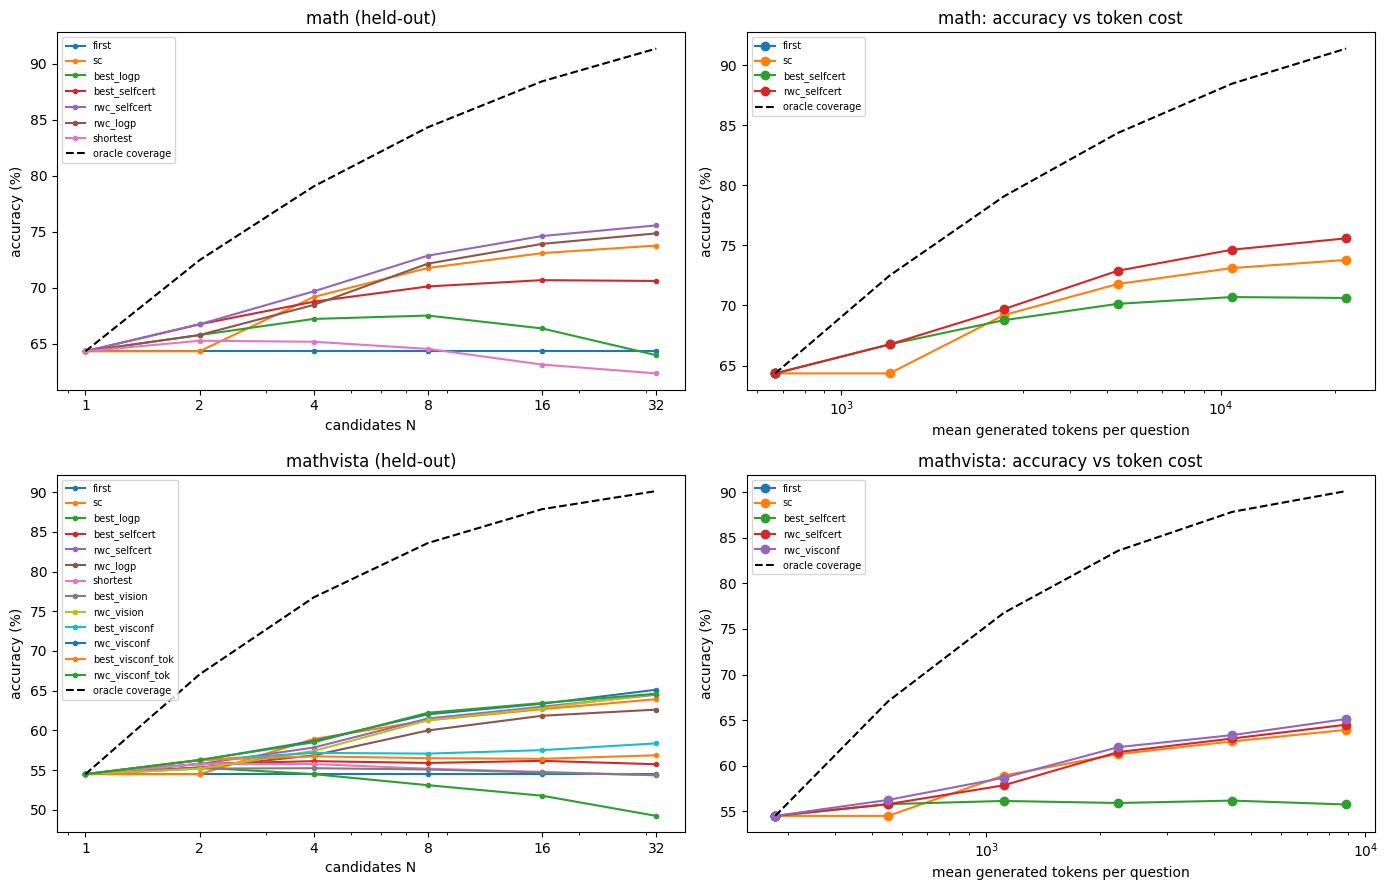

In [7]:
# Step 1 & 2 results — accuracy / coverage / cost curves, failure decomposition, method comparison with paired bootstrap
def paired_boot(a, b, seed=SEED):
    rng = np.random.default_rng(seed); n = len(a); d = np.asarray(a) - np.asarray(b)
    idx = rng.integers(0, n, size=(N_BOOT, n)); m = d[idx].mean(1)
    return float(d.mean()), float(np.quantile(m, .025)), float(np.quantile(m, .975))

tables = []
for nm, res in OFF.items():
    for split in ["eval", "dev"]:
        sids = SPLITS[nm][split]
        for ni, N in enumerate(NS):
            row = {"model_dataset": nm, "split": split, "N": N,
                   "oracle_coverage": 100 * np.mean([res[s]["coverage"][ni] for s in sids]),
                   "distinct_groups": np.mean([res[s]["n_groups"][ni] for s in sids]),
                   "tokens_all_candidates": np.mean([res[s]["cost"][ni] for s in sids]),
                   "tokens_firstans": np.mean([res[s]["cost_first"][ni] for s in sids])}
            for m in methods_for(nm): row[m] = 100 * np.mean([res[s]["acc"][m][ni] for s in sids])
            # decomposition of SC failures: no correct candidate vs correct candidate available but missed
            nc = np.mean([np.mean(1 - res[s]["coverage_orders"][:, ni]) for s in sids])
            miss = np.mean([np.mean(res[s]["coverage_orders"][:, ni] * (1 - res[s]["acc_orders"]["sc"][:, ni])) for s in sids])
            row.update(sc_fail_no_correct_candidate=100 * nc, sc_fail_correct_missed=100 * miss)
            tables.append(row)
TAB = pd.DataFrame(tables); TAB.to_csv(ROOT / "offline" / "accuracy_by_budget.csv", index=False)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
print(TAB[TAB.split == "eval"].round(2))

boot_rows = []
for nm, res in OFF.items():
    sids = SPLITS[nm]["eval"]
    for ni, N in enumerate(NS):
        base = {"sc": [res[s]["acc"]["sc"][ni] for s in sids], "first": [res[s]["acc"]["first"][ni] for s in sids]}
        for m in methods_for(nm):
            a = [res[s]["acc"][m][ni] for s in sids]
            for ref in ["sc", "first"]:
                if m == ref: continue
                d, lo, hi = paired_boot(a, base[ref])
                boot_rows.append({"model_dataset": nm, "N": N, "method": m, "vs": ref,
                                  "diff_pp": 100 * d, "CI95_lo": 100 * lo, "CI95_hi": 100 * hi})
BOOT = pd.DataFrame(boot_rows); BOOT.to_csv(ROOT / "offline" / "paired_bootstrap_vs_sc_first.csv", index=False)
print(BOOT[(BOOT.N == 32) & (BOOT.vs == "sc")].round(2))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(len(OFF), 2, figsize=(14, 4.5 * len(OFF)), squeeze=False)
for r, nm in enumerate(OFF):
    t = TAB[(TAB.model_dataset == nm) & (TAB.split == "eval")]
    for m in methods_for(nm): ax[r, 0].plot(t.N, t[m], marker="o", ms=3, label=m)
    ax[r, 0].plot(t.N, t.oracle_coverage, "k--", label="oracle coverage")
    ax[r, 0].set(xscale="log", xticks=NS, xticklabels=NS, xlabel="candidates N", ylabel="accuracy (%)", title=f"{nm} (held-out)")
    for m in ["first", "sc", "best_selfcert", "rwc_selfcert"] + (["rwc_visconf"] if nm == "mathvista" else []):
        x = t.tokens_firstans if m == "first" else t.tokens_all_candidates
        ax[r, 1].plot(x, t[m], marker="o", label=m)
    ax[r, 1].plot(t.tokens_all_candidates, t.oracle_coverage, "k--", label="oracle coverage")
    ax[r, 1].set(xscale="log", xlabel="mean generated tokens per question", ylabel="accuracy (%)", title=f"{nm}: accuracy vs token cost")
    ax[r, 0].legend(fontsize=7); ax[r, 1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(ROOT / "figures" / "accuracy_coverage_cost.png", dpi=150); plt.show()

   model_dataset                 signal  spearman_with_length  spearman_with_correct (mixed qs)  top_minus_bottom_quartile_correct_pp (all qs)  top_minus_bottom_quartile_correct_pp (mixed qs)  n_mixed_questions
0           math               length_T                 1.000                            -0.076                                         -4.594                                           -7.836                469
1           math  neg_length (shortest)                -1.000                             0.076                                          4.562                                            7.783                469
2           math            mean_logp L                 0.225                             0.134                                          7.828                                           13.353                469
3           math       self_certainty K                -0.161                             0.198                                         11.984              

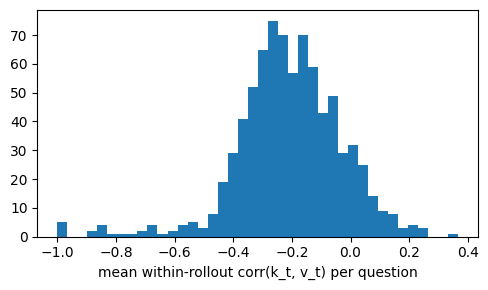

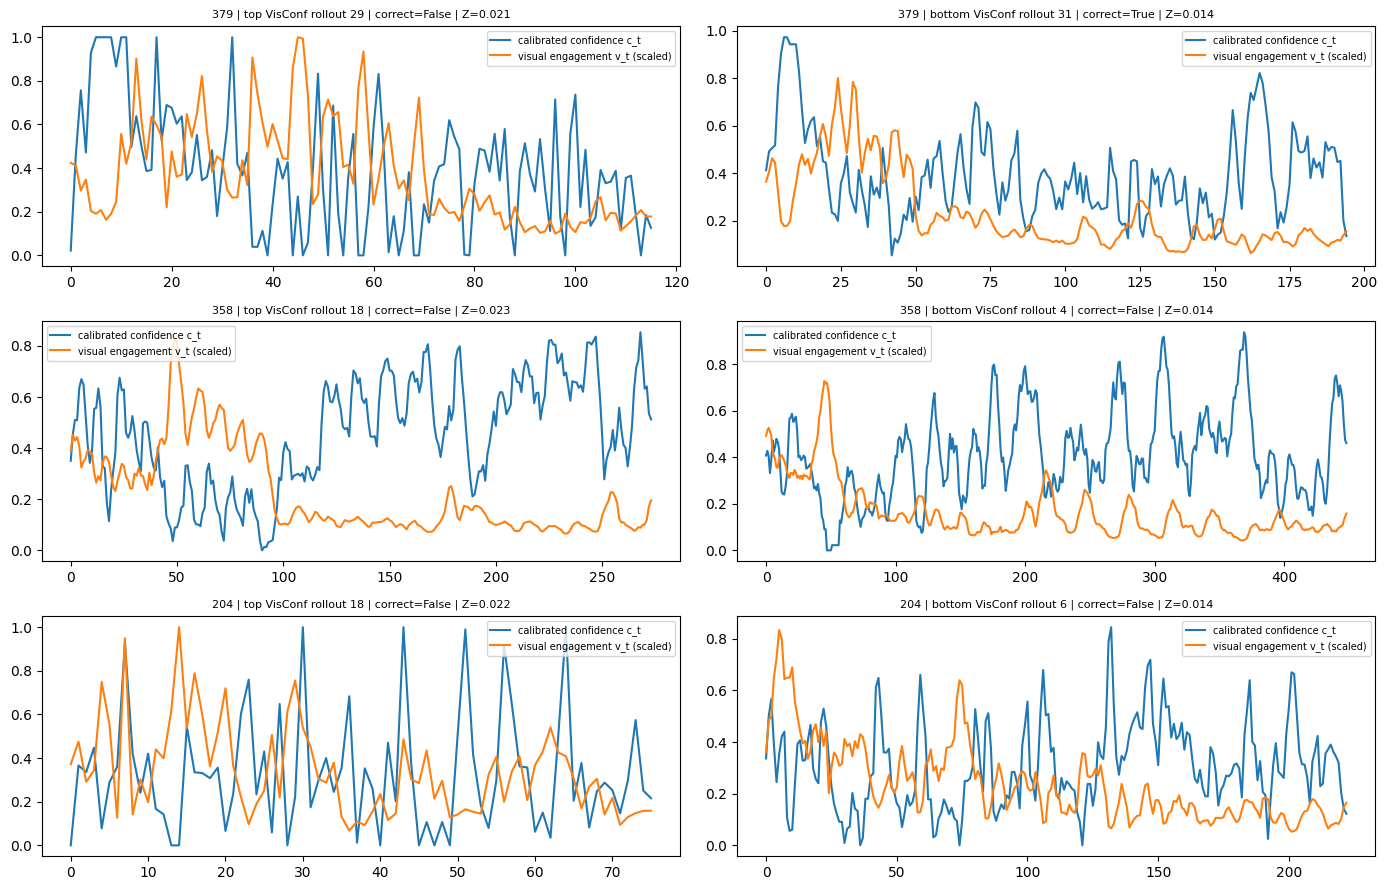

In [8]:
# Step 3 — what the signals capture (N = 32, within-question associations, vision–confidence, tokenwise fusion)
assoc = []
for nm, Q in PREP.items():
    sids = SPLITS[nm]["eval"]
    signals = {"length_T": lambda q: q["T"].astype(float), "neg_length (shortest)": lambda q: -q["T"].astype(float),
               "mean_logp L": lambda q: q["L"], "self_certainty K": lambda q: q["K"]}
    if nm == "mathvista":
        def _vc(q, which):
            C, Z, Zt = visconf_scores(q, np.arange(len(q["gid"])))
            return {"C": C, "Z": Z, "Zt": Zt}[which]
        signals.update({"vision V": lambda q: q["V"], "calibrated conf C": lambda q: _vc(q, "C"),
                        "VisConf Z": lambda q: _vc(q, "Z"), "tokenwise Z_token": lambda q: _vc(q, "Zt")})
    for sname, fn in signals.items():
        rho_len, rho_corr, qdiff, qdiff_mixed = [], [], [], []
        for sid in sids:
            q = Q[sid]; s = np.nan_to_num(fn(q), neginf=-1e9); y = q["correct"].astype(float)
            if np.std(s) > 0 and np.std(q["T"]) > 0: rho_len.append(spearmanr(s, q["T"])[0])
            order = np.lexsort((np.arange(len(s)), -s))           # descending score, ties by rollout index
            k = len(s) // 4
            d = y[order[:k]].mean() - y[order[-k:]].mean()
            qdiff.append(d)
            if 0 < y.mean() < 1:
                qdiff_mixed.append(d)
                if np.std(s) > 0: rho_corr.append(spearmanr(s, y)[0])
        assoc.append({"model_dataset": nm, "signal": sname, "spearman_with_length": np.nanmean(rho_len),
                      "spearman_with_correct (mixed qs)": np.nanmean(rho_corr),
                      "top_minus_bottom_quartile_correct_pp (all qs)": 100 * np.mean(qdiff),
                      "top_minus_bottom_quartile_correct_pp (mixed qs)": 100 * np.mean(qdiff_mixed) if qdiff_mixed else np.nan,
                      "n_mixed_questions": len(qdiff_mixed)})
ASSOC = pd.DataFrame(assoc); ASSOC.to_csv(ROOT / "offline" / "signal_associations_N32.csv", index=False); print(ASSOC.round(3))

if "mathvista" in PREP:
    Q = PREP["mathvista"]; per_q, cov_check = [], []
    for sid in SPLITS["mathvista"]["eval"]:
        q = Q[sid]; rs = []
        C, Z, Zt = visconf_scores(q, np.arange(len(q["gid"])))
        for k, v in zip(q["k_tok"], q["v_tok"]):
            if len(k) >= 3 and np.std(k) > 0 and np.std(v) > 0: rs.append(pearsonr(k, v)[0])
        if rs: per_q.append(np.mean(rs))
        # identity check: Z_token - Z = Cov_t(c, v) (population covariance over tokens)
        lo, hi = np.percentile(np.concatenate(q["k_tok"]), [5, 95])
        for j, (k, v) in enumerate(zip(q["k_tok"], q["v_tok"])):
            if len(k):
                c = np.clip((k - lo) / max(hi - lo, 1e-8), 0, 1)
                cov_check.append(abs((Zt[j] - Z[j]) - np.mean((c - c.mean()) * (v - v.mean()))))
    per_q = np.array(per_q)
    cv = {"n_questions": len(per_q), "mean_within_rollout_corr(k,v)": per_q.mean(), "median": np.median(per_q),
          "q25": np.quantile(per_q, .25), "q75": np.quantile(per_q, .75), "frac_questions_negative": (per_q < 0).mean(),
          "max_abs_identity_error_Ztok_minus_Z_vs_cov": float(np.max(cov_check))}
    json.dump(cv, open(ROOT / "offline" / "mathvista_confidence_vision_corr.json", "w"), indent=1, default=float); print(cv)
    plt.figure(figsize=(5, 3)); plt.hist(per_q, bins=40); plt.xlabel("mean within-rollout corr(k_t, v_t) per question")
    plt.tight_layout(); plt.savefig(ROOT / "figures" / "mathvista_conf_vision_corr_hist.png", dpi=150); plt.show()

    # illustrative trajectories. Rule: the first 3 held-out questions (split order) where highest-VisConf and
    # self-consistency disagree at N=32 (order 0); plot c_t and v_t of the top- and bottom-VisConf rollouts.
    chosen = []
    for sid in SPLITS["mathvista"]["eval"]:
        q = Q[sid]; idx = ORDERS["mathvista"][sid][0]
        sel = select_all_methods("mathvista", q, idx)
        if sel["best_visconf"] != sel["sc"]: chosen.append(sid)
        if len(chosen) == 3: break
    fig, axs = plt.subplots(max(1, len(chosen)), 2, figsize=(14, 3 * max(1, len(chosen))), squeeze=False)
    for r, sid in enumerate(chosen):
        q = Q[sid]; allidx = np.arange(len(q["gid"])); C, Z, Zt = visconf_scores(q, allidx)
        lo, hi = np.percentile(np.concatenate(q["k_tok"]), [5, 95])
        for c_, j in enumerate([int(np.argmax(Z)), int(np.argmin(np.where(np.isfinite(Z), Z, np.inf)))]):
            k, v = q["k_tok"][j], q["v_tok"][j]; cc = np.clip((k - lo) / max(hi - lo, 1e-8), 0, 1)
            w = max(1, len(k) // 60); sm = lambda x: np.convolve(x, np.ones(w) / w, mode="valid")
            axs[r, c_].plot(sm(cc), label="calibrated confidence c_t"); axs[r, c_].plot(sm(v) / max(v.max(), 1e-9), label="visual engagement v_t (scaled)")
            axs[r, c_].set_title(f"{sid} | {'top' if c_ == 0 else 'bottom'} VisConf rollout {q['rollout_ids'][j]} | "
                                 f"correct={bool(q['correct'][j])} | Z={Z[j]:.3f}", fontsize=8)
            axs[r, c_].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(ROOT / "figures" / "mathvista_trajectories.png", dpi=130); plt.show()

In [9]:
# Step 4 — live generation on 50 MATH held-out questions: single long vs parallel x3 vs sequential refinement (GPU)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

def last_boxed(s):
    """README.MD rule: find the LAST literal '\\boxed{', scan balanced braces (nested LaTeX kept), strip whitespace.
    An absent, empty or unclosed last box gives None; no numeric fallback."""
    if s is None: return None
    i = s.rfind("\\boxed{")
    if i < 0: return None
    start = i + len("\\boxed{"); depth = 1
    for e in range(start, len(s)):
        if s[e] == "{": depth += 1
        elif s[e] == "}":
            depth -= 1
            if depth == 0:
                out = s[start:e].strip()
                return out if out else None
    return None

def problem_text(sid):
    df, cols = DATA["math"]
    row = df[df[cols["sample_id"]] == sid].iloc[0]
    if cols["problem"]: return str(row[cols["problem"]]).split(LIVE_INSTR)[0].rstrip()
    for c in ["prompt", "input", "prompt_text"]:          # fall back to the stored chat prompt
        if c in df.columns:
            t = str(row[c]); m = re.search(r"<\|im_start\|>user\n(.*?)<\|im_end\|>", t, re.S)
            t = m.group(1) if m else t
            return t.split(LIVE_INSTR)[0].rstrip()
    raise KeyError("no problem text column found; set COL_OVERRIDES['problem']")

LIVE_IDS = SPLITS["math"]["eval"][:LIVE_N]
try:
    print("live question example:\n", problem_text(LIVE_IDS[0])[:400])
except Exception as e:
    print("!! cannot find the MATH problem text — set COL_OVERRIDES['problem'] before the live step:", e)
LIVE_LOG = ROOT / "live" / "calls.jsonl"
done = {}
if LIVE_LOG.exists():
    for l in open(LIVE_LOG):
        r = json.loads(l); done[(r["sample_id"], r["call"])] = r

if not torch.cuda.is_available():
    print("No GPU in this runtime: skipping live generation (Steps 1–3 and 5–6 still run). Re-run on a GPU for Step 4.")
elif len(done) < LIVE_N * 5:
    ltok = AutoTokenizer.from_pretrained(LIVE_MODEL, revision=LIVE_REVISION)
    lmod = AutoModelForCausalLM.from_pretrained(LIVE_MODEL, revision=LIVE_REVISION, torch_dtype=torch.float16,
                                                attn_implementation="sdpa").cuda().eval()   # FP16, no quantisation
    EOS = [ltok.convert_tokens_to_ids("<|im_end|>"), ltok.eos_token_id]

    def call(messages, max_new, seed):
        prompt = ltok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        ids = ltok(prompt, return_tensors="pt", add_special_tokens=False).to("cuda")
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t0 = time.time()
        with torch.no_grad():
            out = lmod.generate(**ids, max_new_tokens=max_new, eos_token_id=EOS, pad_token_id=ltok.eos_token_id, **GEN_KW)
        torch.cuda.synchronize(); dt = time.time() - t0
        new = out[0, ids["input_ids"].shape[1]:].tolist()
        finished = any(t in EOS for t in new)
        n_out = next((i + 1 for i, t in enumerate(new) if t in EOS), len(new))
        text = ltok.decode(new[:n_out], skip_special_tokens=True)
        return {"prompt": prompt, "response": text, "seed": seed, "input_tokens": ids["input_ids"].shape[1],
                "output_tokens": n_out, "truncated": (not finished) and n_out >= max_new, "time_s": dt,
                "peak_mem_GB": torch.cuda.max_memory_allocated() / 2**30, "max_new_tokens": max_new}

    def log(sid, name, rec):
        rec = {"sample_id": str(sid), "call": name, **rec, "extracted": last_boxed(rec["response"])}
        with open(LIVE_LOG, "a") as f: f.write(json.dumps(rec) + "\n")
        done[(str(sid), name)] = rec; return rec

    t_all = time.time()
    for qi, sid in enumerate(LIVE_IDS):
        base_msgs = [{"role": "system", "content": LIVE_SYSTEM},
                     {"role": "user", "content": problem_text(sid) + LIVE_SEP + LIVE_INSTR}]
        seed0 = SEED * 1000 + qi * 10                     # independent seeds per call
        if (str(sid), "single") not in done: log(sid, "single", call(base_msgs, 3072, seed0 + 0))
        for k in range(3):
            if (str(sid), f"parallel_{k}") not in done: log(sid, f"parallel_{k}", call(base_msgs, 1024, seed0 + 1 + k))
        if (str(sid), "revision") not in done:
            init = done[(str(sid), "parallel_0")]["response"]          # first parallel response = initial response
            msgs = base_msgs + [{"role": "assistant", "content": init}, {"role": "user", "content": REVIEW_INSTR}]
            log(sid, "revision", call(msgs, 2048, seed0 + 4))
        print(f"live {qi + 1}/{LIVE_N} done ({(time.time() - t_all) / 60:.1f} min)")
    del lmod; gc.collect(); torch.cuda.empty_cache()

live question example:
 The arithmetic mean (or average) of $A$, $B$ and $C$ is 10. The value of $A$ is six less than the value of $B$, and the value of $C$ is three more than the value of $B$. What is the value of $C$?


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (5 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

live 1/50 done (0.0 min)
live 2/50 done (0.0 min)
live 3/50 done (0.0 min)
live 4/50 done (0.0 min)
live 5/50 done (0.0 min)
live 6/50 done (0.0 min)
live 7/50 done (0.0 min)
live 8/50 done (0.0 min)
live 9/50 done (0.0 min)
live 10/50 done (0.0 min)
live 11/50 done (0.0 min)
live 12/50 done (0.0 min)
live 13/50 done (0.0 min)
live 14/50 done (0.0 min)
live 15/50 done (0.0 min)
live 16/50 done (0.0 min)
live 17/50 done (0.0 min)
live 18/50 done (0.0 min)
live 19/50 done (0.0 min)
live 20/50 done (0.0 min)
live 21/50 done (5.0 min)
live 22/50 done (7.5 min)
live 23/50 done (10.6 min)
live 24/50 done (13.4 min)
live 25/50 done (15.0 min)
live 26/50 done (17.6 min)
live 27/50 done (19.4 min)
live 28/50 done (21.4 min)
live 29/50 done (27.2 min)
live 30/50 done (30.1 min)
live 31/50 done (31.4 min)
live 32/50 done (33.9 min)
live 33/50 done (38.2 min)
live 34/50 done (42.0 min)
live 35/50 done (45.1 min)
live 36/50 done (49.5 min)
live 37/50 done (55.0 min)
live 38/50 done (56.5 min)
live 

In [10]:
# Step 4b — live results: accuracy, actual tokens, runtime, truncation/extraction, revision transitions
if len(done) >= LIVE_N * 5:
    Qm = PREP["math"]
    def grade(sid, ans):
        if is_missing(ans): return False
        gid, gc_, _ = group_math([ans], str(Qm[sid]["gold"])); return bool(gc_[gid[0]]) if gid[0] >= 0 else False
    rows, trans = [], Counter()
    for sid in LIVE_IDS:
        s = str(sid); R_ = {c: done[(s, c)] for c in ["single", "parallel_0", "parallel_1", "parallel_2", "revision"]}
        par = [R_[f"parallel_{k}"]["extracted"] for k in range(3)]
        gid, gcor, reps = group_math(par, str(Qm[sid]["gold"]))
        best = vote(np.array(gid))[0]
        init_ok, rev_ok = grade(sid, par[0]), grade(sid, R_["revision"]["extracted"])
        trans[("C" if init_ok else "W") + "->" + ("C" if rev_ok else "W")] += 1
        cost = lambda calls: (sum(R_[c]["input_tokens"] for c in calls), sum(R_[c]["output_tokens"] for c in calls),
                              sum(R_[c]["time_s"] for c in calls))
        for strat, calls, ok, ext in [
            ("single_3072", ["single"], grade(sid, R_["single"]["extracted"]), [R_["single"]["extracted"]]),
            ("parallel_3x1024_sc", ["parallel_0", "parallel_1", "parallel_2"], bool(gcor[best]) if best >= 0 else False, par),
            ("sequential_1024+2048", ["parallel_0", "revision"], rev_ok, [R_["revision"]["extracted"]])]:
            i_, o_, t_ = cost(calls)
            rows.append({"sample_id": s, "strategy": strat, "correct": float(ok), "input_tokens": i_, "output_tokens": o_,
                         "runtime_s": t_, "truncation_rate": np.mean([R_[c]["truncated"] for c in calls]),
                         "extraction_rate": np.mean([e is not None for e in ext]),
                         "peak_mem_GB": max(R_[c]["peak_mem_GB"] for c in calls)})
    LV = pd.DataFrame(rows); LV.to_csv(ROOT / "live" / "per_question.csv", index=False)
    LS = LV.groupby("strategy").agg(accuracy=("correct", lambda x: 100 * x.mean()), input_tokens=("input_tokens", "mean"),
                                    output_tokens=("output_tokens", "mean"), runtime_s=("runtime_s", "mean"),
                                    truncation_rate=("truncation_rate", "mean"), extraction_rate=("extraction_rate", "mean"),
                                    peak_mem_GB=("peak_mem_GB", "max"))
    LS.to_csv(ROOT / "live" / "summary.csv"); print(LS.round(3)); print("revision transitions vs shared initial answer:", dict(trans))
    json.dump(dict(trans), open(ROOT / "live" / "revision_transitions.json", "w"))
    piv = LV.pivot(index="sample_id", columns="strategy", values="correct")
    for a, b in [("parallel_3x1024_sc", "single_3072"), ("sequential_1024+2048", "single_3072"), ("sequential_1024+2048", "parallel_3x1024_sc")]:
        print(f"{a} − {b}: diff/CI95 (pp) =", [round(100 * x, 1) for x in paired_boot(piv[a].values, piv[b].values)])
else:
    print("live generation incomplete:", len(done), "/", LIVE_N * 5, "calls")

                      accuracy  input_tokens  output_tokens  runtime_s  truncation_rate  extraction_rate  peak_mem_GB
strategy                                                                                                             
parallel_3x1024_sc        54.0        325.14        1859.52    108.247            0.167            0.833        5.935
sequential_1024+2048      62.0        889.62        1218.74     71.362            0.100            1.000        6.173
single_3072               62.0        108.38         761.32     45.004            0.040            0.960        6.086
revision transitions vs shared initial answer: {'C->C': 28, 'W->W': 19, 'W->C': 3}
parallel_3x1024_sc − single_3072: diff/CI95 (pp) = [-8.0, -20.0, 6.0]
sequential_1024+2048 − single_3072: diff/CI95 (pp) = [0.0, -12.0, 12.0]
sequential_1024+2048 − parallel_3x1024_sc: diff/CI95 (pp) = [8.0, 0.0, 18.0]


In [11]:
# Step 5 — adaptive sampling (agreement-based vs quality-aware stopping), thresholds chosen on dev only
def stop_stats(nm, q, idx):
    """Evidence available after revealing idx: SC answer, unique non-NO_ANSWER leader share, RWC winner and margin."""
    g = q["gid"][idx]; n = len(idx)
    sc, cnt = vote(g)
    top = max(cnt.values()); leaders = [a for a, c in cnt.items() if c == top]
    unique_lead = len(leaders) == 1 and leaders[0] != -1
    score = visconf_scores(q, idx)[1] if nm == "mathvista" else q["K"][idx]       # VisConf / self-certainty
    rw, W = vote(g, rwc_weights(score))
    vals = sorted(W.values(), reverse=True); tot = sum(vals)
    margin = (vals[0] - (vals[1] if len(vals) > 1 else 0.0)) / tot if tot > 0 else 0.0
    return {"sc": sc, "share": top / n, "unique": unique_lead, "rwc": rw, "margin": margin,
            "cost": q["cost"][idx].sum()}

def precompute_adaptive(nm):
    path = ROOT / "adaptive" / f"{nm}_stop_stats.pkl"
    if path.exists(): return pd.read_pickle(path)
    Q = PREP[nm]; out = {}
    for sid, q in Q.items():
        out[sid] = [{n: stop_stats(nm, q, perm[:n]) for n in CHECKS + [32]} for perm in ORDERS[nm][sid]]
    pd.to_pickle(out, path); return out

def simulate(nm, ST, sids, policy, tau=None, gamma=None):
    """Returns per-question mean accuracy, cost, rollouts (averaged over orders) and stopping counts."""
    Q = PREP[nm]; acc, cost, nro, stops, early_wrong = [], [], [], Counter(), []
    for sid in sids:
        a_, c_, n_ = [], [], []
        for o, st in enumerate(ST[sid]):
            stop_n = 32
            if policy != "fixed32":
                for n in CHECKS:
                    s = st[n]
                    ok = s["unique"] and s["share"] >= tau - 1e-12
                    if policy == "quality": ok = ok and s["sc"] == s["rwc"] and s["margin"] >= gamma - 1e-12
                    if ok: stop_n = n; break
            s = st[stop_n]; corr = bool(Q[sid]["group_correct"][s["sc"]])
            a_.append(corr); c_.append(s["cost"]); n_.append(stop_n); stops[stop_n] += 1
            if stop_n < 32 and not corr:
                early_wrong.append({"sample_id": sid, "order": o, "stopped_at": stop_n,
                                    "fixed32_correct": bool(Q[sid]["group_correct"][st[32]["sc"]]),
                                    "pool_frac_correct": float(Q[sid]["correct"].mean()), "share": s["share"]})
        acc.append(np.mean(a_)); cost.append(np.mean(c_)); nro.append(np.mean(n_))
    return {"acc": np.array(acc), "cost": np.array(cost), "rollouts": np.array(nro), "stops": stops, "early_wrong": early_wrong}

ADAPT = []
for nm in FOLDERS:
    ST = precompute_adaptive(nm)
    dev, ev = SPLITS[nm]["dev"], SPLITS[nm]["eval"]
    ref = simulate(nm, ST, dev, "fixed32")["acc"].mean()
    chosen = {}
    for fam, grid in [("agreement", [(t, None) for t in TAUS]), ("quality", [(t, g) for t in TAUS for g in GAMMAS])]:
        cands = [{"tau": None, "gamma": None, "fallback32": True, "acc": ref,
                  "cost": simulate(nm, ST, dev, "fixed32")["cost"].mean()}]
        for t, g in grid:
            r = simulate(nm, ST, dev, fam, t, g); cands.append({"tau": t, "gamma": g, "fallback32": False,
                                                              "acc": r["acc"].mean(), "cost": r["cost"].mean()})
        pd.DataFrame(cands).to_csv(ROOT / "adaptive" / f"{nm}_{fam}_dev_grid.csv", index=False)
        ok = [c for c in cands if c["acc"] >= ref - 0.01]                      # within 1 pp of fixed-32 SC
        best = sorted(ok, key=lambda c: (c["cost"], -c["acc"], c["tau"] if c["tau"] is not None else 9,
                                         c["gamma"] if c["gamma"] is not None else 9))[0]
        chosen[fam] = best
    json.dump(chosen, open(ROOT / "adaptive" / f"{nm}_selected_settings.json", "w"), indent=1, default=float)
    print(nm, "dev fixed-32 SC acc", round(100 * ref, 2), "| selected:", chosen)
    # held-out evaluation with frozen settings
    fixed = {N: np.array([OFF[nm][s]["acc"]["sc"][NS.index(N)] for s in ev]) for N in NS}
    fixed_cost = {N: np.array([OFF[nm][s]["cost"][NS.index(N)] for s in ev]) for N in NS}
    for N in NS:
        ADAPT.append({"model_dataset": nm, "policy": f"fixed-{N} SC", "accuracy": 100 * fixed[N].mean(),
                      "mean_tokens": fixed_cost[N].mean(), "mean_rollouts": N})
    for fam, c in chosen.items():
        pol = "fixed32" if c["fallback32"] else fam
        r = simulate(nm, ST, ev, pol, c["tau"], c["gamma"])
        d, lo, hi = paired_boot(r["acc"], fixed[32])
        tot = sum(r["stops"].values())
        ADAPT.append({"model_dataset": nm, "policy": f"{fam} (tau={c['tau']}, gamma={c['gamma']})",
                      "accuracy": 100 * r["acc"].mean(), "mean_tokens": r["cost"].mean(), "mean_rollouts": r["rollouts"].mean(),
                      "vs_fixed32_pp": 100 * d, "CI95": (100 * lo, 100 * hi),
                      **{f"stop@{n}_%": 100 * r["stops"][n] / tot for n in CHECKS + [32]}})
        ew = pd.DataFrame(r["early_wrong"]); ew.to_csv(ROOT / "adaptive" / f"{nm}_{fam}_incorrect_early_stops.csv", index=False)
        if len(ew):
            print(f"{nm}/{fam}: {len(ew)} incorrect early stops (question×order); fixed-32 would recover "
                  f"{100 * ew.fixed32_correct.mean():.1f}% of them")
AD = pd.DataFrame(ADAPT); AD.to_csv(ROOT / "adaptive" / "heldout_results.csv", index=False); print(AD.round(2))

math dev fixed-32 SC acc 82.5 | selected: {'agreement': {'tau': 0.625, 'gamma': None, 'fallback32': False, 'acc': np.float64(0.826), 'cost': np.float64(7088.9555)}, 'quality': {'tau': 0.5, 'gamma': 0.0, 'fallback32': False, 'acc': np.float64(0.8215), 'cost': np.float64(5479.528499999999)}}
math/agreement: 660 incorrect early stops (question×order); fixed-32 would recover 7.7% of them
math/quality: 1152 incorrect early stops (question×order); fixed-32 would recover 11.4% of them
mathvista dev fixed-32 SC acc 64.25 | selected: {'agreement': {'tau': 0.5, 'gamma': None, 'fallback32': False, 'acc': np.float64(0.6365), 'cost': np.float64(3644.9230000000007)}, 'quality': {'tau': 0.5, 'gamma': 0.0, 'fallback32': False, 'acc': np.float64(0.64), 'cost': np.float64(4071.1344999999997)}}
mathvista/agreement: 1990 incorrect early stops (question×order); fixed-32 would recover 16.8% of them
mathvista/quality: 1748 incorrect early stops (question×order); fixed-32 would recover 15.1% of them
   model_

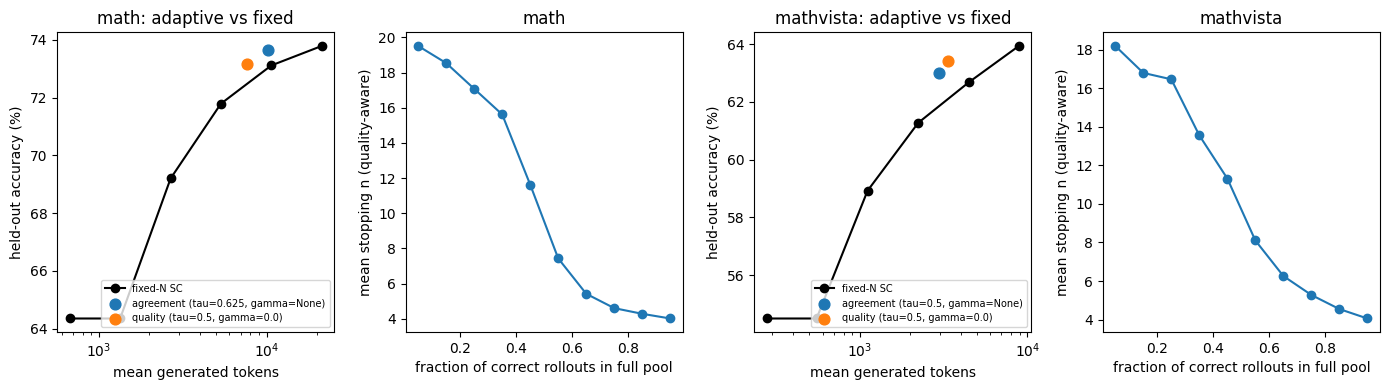


===== math: selection disagreements =====
[test:1577] gold='14' | SC='14' (✓) | best-K='5' (✗) | votes=[('14', 24), ('20', 3), ('5', 2), ('12', 1)]
[test:2892] gold='-71' | SC='1' (✗) | best-K='44' (✗) | votes=[('0', 4), ('1', 4), ('23', 2), ('-1', 1)]
[test:4702] gold='59' | SC='-59' (✗) | best-K='59' (✓) | votes=[('-59', 10), ('59', 6), ('-1', 4), ('NO_ANSWER', 3)]

===== mathvista: selection disagreements =====
[358] gold='A' | SC='A' (✓) | best-K='E' (✗) | votes=[('A', 14), ('D', 7), ('E', 5), ('C', 3)]
[204] gold='12' | SC='4' (✗) | best-K='NO_ANSWER' (✗) | votes=[('4', 7), ('NO_ANSWER', 6), ('1', 3), ('0', 3)]
[165] gold='6' | SC='7' (✗) | best-K='NO_ANSWER' (✗) | votes=[('9', 5), ('7', 5), ('4', 3), ('6', 3)]

All Task 3 outputs are in /content/drive/MyDrive/ATML_PA3/task3


In [12]:
# Step 6 — compute allocation: adaptive vs fixed budgets, stopping vs agreement / pool difficulty
fig, ax = plt.subplots(1, 2 * len(FOLDERS), figsize=(7 * len(FOLDERS), 4), squeeze=False)
for i, nm in enumerate(FOLDERS):
    a = AD[AD.model_dataset == nm]; fx = a[a.policy.str.startswith("fixed")]
    ax[0, 2 * i].plot(fx.mean_tokens, fx.accuracy, "ko-", label="fixed-N SC")
    for _, r in a[~a.policy.str.startswith("fixed")].iterrows():
        ax[0, 2 * i].scatter(r.mean_tokens, r.accuracy, s=60, label=r.policy)
    ax[0, 2 * i].set(xscale="log", xlabel="mean generated tokens", ylabel="held-out accuracy (%)", title=f"{nm}: adaptive vs fixed")
    ax[0, 2 * i].legend(fontsize=7)
    # stopping point vs fraction of correct rollouts in the full pool (retrospective only)
    ST = precompute_adaptive(nm); c = json.load(open(ROOT / "adaptive" / f"{nm}_selected_settings.json"))["quality"]
    xs, ys = [], []
    if not c["fallback32"]:
        for sid in SPLITS[nm]["eval"]:
            for st in ST[sid]:
                stop_n = 32
                for n in CHECKS:
                    s = st[n]
                    if s["unique"] and s["share"] >= c["tau"] and s["sc"] == s["rwc"] and s["margin"] >= c["gamma"]: stop_n = n; break
                xs.append(PREP[nm][sid]["correct"].mean()); ys.append(stop_n)
        xs, ys = np.array(xs), np.array(ys); bins = np.linspace(0, 1, 11); mid = (bins[:-1] + bins[1:]) / 2
        mean_stop = [ys[(xs >= lo) & (xs < hi + (hi == 1))].mean() if ((xs >= lo) & (xs < hi + (hi == 1))).any() else np.nan
                     for lo, hi in zip(bins[:-1], bins[1:])]
        ax[0, 2 * i + 1].plot(mid, mean_stop, "o-")
    ax[0, 2 * i + 1].set(xlabel="fraction of correct rollouts in full pool", ylabel="mean stopping n (quality-aware)", title=nm)
plt.tight_layout(); plt.savefig(ROOT / "figures" / "adaptive_vs_fixed.png", dpi=150); plt.show()

# representative cases (stated rule): for each dataset, the first 3 held-out questions (split order) in which
# (a) SC and best self-certainty disagree at N=32, order 0; printed with answers, votes and correctness.
for nm in FOLDERS:
    Q = PREP[nm]; shown = 0
    print(f"\n===== {nm}: selection disagreements =====")
    for sid in SPLITS[nm]["eval"]:
        q = Q[sid]; idx = ORDERS[nm][sid][0]; sel = select_all_methods(nm, q, idx)
        if sel["sc"] == sel["best_selfcert"]: continue
        name = lambda gid: q["reps"][gid] if gid >= 0 else NO_ANSWER
        votes = Counter(name(g) for g in q["gid"])
        print(f"[{sid}] gold={q['gold']!r} | SC={name(sel['sc'])!r} ({'✓' if q['group_correct'][sel['sc']] else '✗'}) | "
              f"best-K={name(sel['best_selfcert'])!r} ({'✓' if q['group_correct'][sel['best_selfcert']] else '✗'}) | "
              f"votes={votes.most_common(4)}")
        shown += 1
        if shown == 3: break
print("\nAll Task 3 outputs are in", ROOT)